# 6. Us vs the leaderboard: error budget, our confusion matrices, and what each error costs

The leaderboard gives each team's macro F1 and accuracy per task on the 81 test flows. This notebook compares our entry
with the leaders using only those public numbers and our own cross-validation predictions:

1. **Error budget** from the leaderboard: how many of the 81 test flows each team gets wrong, and how many points those
   errors cost.
2. **Our confusion matrices** from cross-validation, scaled to an 81-flow set: where our errors are expected to fall.
3. **What one error costs** in points, by type (true app → predicted app), for a test-sized class mix.

**What this notebook does not do:** it does not reconstruct anyone's test confusion matrix. Many matrices fit one score,
and finding the one that fits exactly would decode test-set information (the test class counts, and for our own entry
which of our predicted test flows are wrong). That is challenge condition 1 territory, and the project's off-limits list
forbids "inferring test labels from score changes". No test labels and no `metadata.json` counts are read. Leaderboard
numbers are used only to size the gap (as in experiment 046), never to choose a model.

Leaderboard snapshot: `submissions/raw/leaderboard-final-test-2026-10-16.json` (read 16 October 2026, 23:20 UTC); our own row
updated to upload 10 (`submissions/raw/leaderboard-final-test-2026-10-21.txt`, 21 October: 90.85). Other teams may have moved since.

In [1]:
# Setup: find the project root (the folder that holds data/official).
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.metrics import confusion_matrix

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "official").exists())
APPS = ["facebook", "google", "instagram", "mozilla", "x", "youtube"]
N_TEST = 81
US, OTHER, INK, MUTED = "#2a78d6", "#b9b8b1", "#1f2937", "#6b7280"
BLUES = LinearSegmentedColormap.from_list("blues", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d1d5db",
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
                     # fallback fonts so the team name 图个乐呵队 renders (macOS); other systems fall back to DejaVu Sans
                     "font.family": ["DejaVu Sans", "Heiti SC", "Arial Unicode MS"]})

## 1. The error budget, from the leaderboard

Accuracy × 81 gives the number of correct test flows exactly, so the number of errors is exact. "Points lost" is
$50 \times (1 - \text{macro F1})$ per task, and "points per error" divides it by the errors. A team whose errors land
on small apps (facebook, instagram) loses more per error, because macro F1 weights each app equally.

In [2]:
lb = json.loads((ROOT / "submissions/raw/leaderboard-final-test-2026-10-16.json").read_text())
L = pd.DataFrame(lb["entries"]).set_index("team")
# Our row since 21 October (upload 10, submissions/raw/leaderboard-final-test-2026-10-21.txt): Task 1 45.60 points (macro F1
# 0.912) at accuracy 0.90 (73 of 81: 72/81 and 74/81 would show 0.89 and 0.91); Task 2 unchanged. Other teams: 16 October.
L.loc["Telex", ["Task 1 Macro F1", "Task 1 Accuracy", "Total"]] = [45.60 / 50, 73 / N_TEST, 90.85]
L = L.sort_values("Total", ascending=False)
for t in (1, 2):
    L[f"T{t} errors"] = (N_TEST - (L[f"Task {t} Accuracy"] * N_TEST).round()).astype(int)
    L[f"T{t} points lost"] = 50 * (1 - L[f"Task {t} Macro F1"])
    L[f"T{t} points per error"] = L[f"T{t} points lost"] / L[f"T{t} errors"]
cols = ["Task 1 Macro F1", "T1 errors", "T1 points lost", "T1 points per error",
        "Task 2 Macro F1", "T2 errors", "T2 points lost", "T2 points per error", "Total"]
L[cols].round(3)

,Task 1 Macro F1,T1 errors,T1 points lost,T1 points per error,Task 2 Macro F1,T2 errors,T2 points lost,T2 points per error,Total
team,,,,,,,,,
Infralibre,0.964,4,1.787,0.447,0.936,7,3.205,0.458,95.008
HeriTech,0.957,4,2.165,0.541,0.943,6,2.857,0.476,94.978
LLM_ops,0.939,6,3.059,0.510,0.930,7,3.498,0.500,93.443
RahmaniJ,0.925,8,3.750,0.469,0.925,8,3.750,0.469,92.500
Telex,0.912,8,4.400,0.550,0.905,9,4.747,0.527,90.850
Flow State,0.912,7,4.388,0.627,0.867,8,6.626,0.828,88.986
图个乐呵队,0.882,12,5.916,0.493,0.882,12,5.916,0.493,88.169
Artur Baranovsky,0.850,10,7.511,0.751,0.897,10,5.126,0.513,87.363


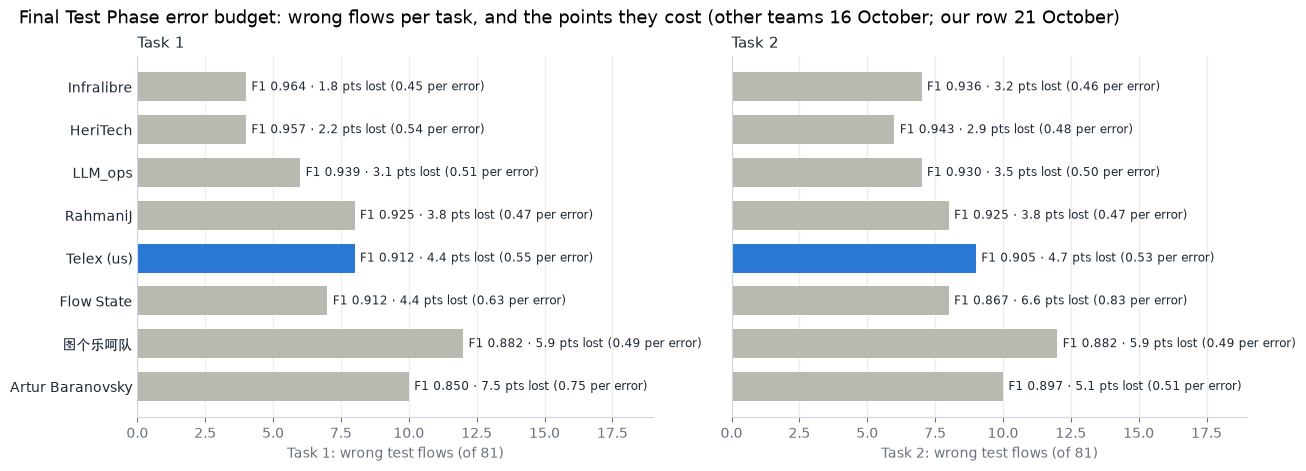

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True, constrained_layout=True)
teams = list(L.index)[::-1]
for ax, t in zip(axes, (1, 2)):
    err = L.loc[teams, f"T{t} errors"].values
    colors = [US if name == "Telex" else OTHER for name in teams]
    ax.barh(range(len(teams)), err, color=colors, height=0.68)
    for y, name in enumerate(teams):
        r = L.loc[name]
        ax.text(err[y] + 0.2, y, f"F1 {r[f'Task {t} Macro F1']:.3f} · {r[f'T{t} points lost']:.1f} pts lost "
                f"({r[f'T{t} points per error']:.2f} per error)", va="center", fontsize=8.5, color=INK)
    ax.set_yticks(range(len(teams)), [f"{n} (us)" if n == "Telex" else n for n in teams])
    ax.tick_params(axis="y", length=0, labelcolor=INK)
    ax.set_xlim(0, 19)
    ax.set_xlabel(f"Task {t}: wrong test flows (of 81)")
    ax.set_title(f"Task {t}", loc="left", fontsize=11, color=INK)
    ax.grid(axis="x", color="#eeeeec", lw=1)
    ax.set_axisbelow(True)
fig.suptitle("Final Test Phase error budget: wrong flows per task, and the points they cost (other teams 16 October; our row 21 October)",
             x=0.01, ha="left", fontsize=13)
plt.show()

## 2. Our confusion matrices from cross-validation, scaled to 81 flows

These are the production models' out-of-fold predictions (the champion runs: every labelled flow predicted 10 times by
models that never saw it), pooled and scaled to one 81-flow set: each count is divided by 10 repeats and multiplied by
81 / 330. So a cell reads "expected wrong flows of this kind in a test-sized set". Colour = share of the true app's
flows. No test data is involved.

findfont: Failed to find font weight bold for Heiti SC, now using 400.


findfont: Failed to find font weight bold for Arial Unicode MS, now using 400.


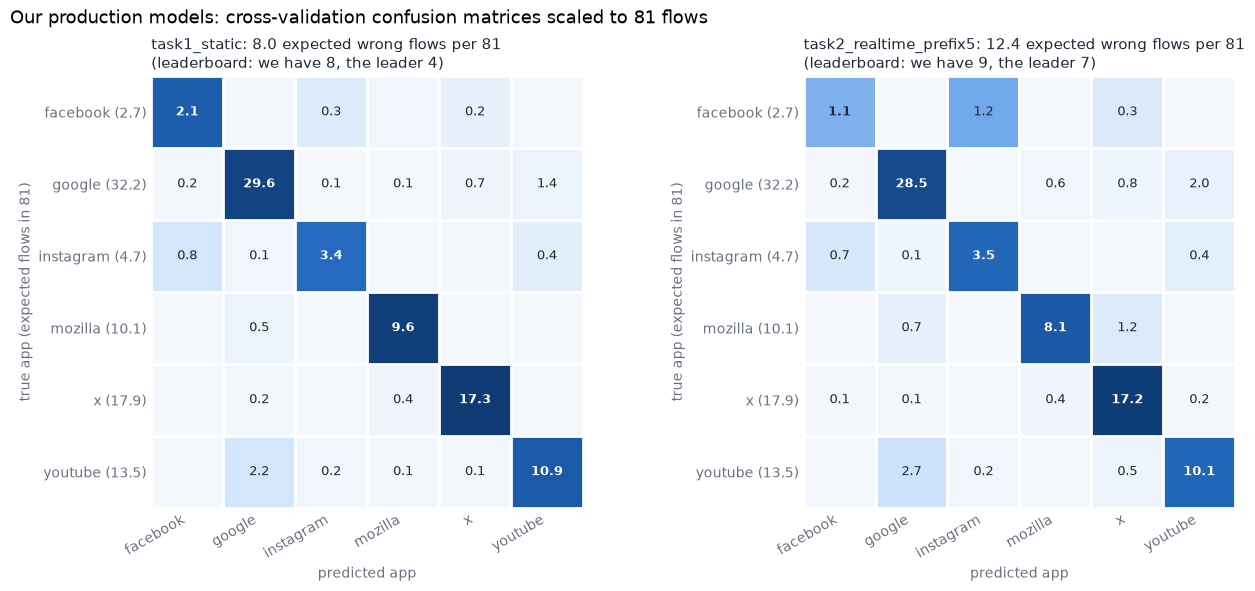

In [4]:
champions = json.loads((ROOT / "results/champions.json").read_text())
SCALED = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), constrained_layout=True)
for ax, task in zip(axes, ["task1_static", "task2_realtime_prefix5"]):
    oof = pd.read_csv(ROOT / "results" / champions[task]["run_id"] / task / "oof.csv")
    cm = confusion_matrix(oof.y_true, oof.y_pred, labels=APPS) / 10 * N_TEST / 330
    SCALED[task] = cm
    share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(share, cmap=BLUES, vmin=0, vmax=1)
    for i in range(6):
        for j in range(6):
            if cm[i, j] >= 0.05:
                ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", fontsize=9,
                        fontweight="bold" if i == j else "normal", color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks(np.arange(-0.5, 6), minor=True)
    ax.set_yticks(np.arange(-0.5, 6), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(6), APPS, rotation=30, ha="right")
    ax.set_yticks(range(6), [f"{a} ({n:.1f})" for a, n in zip(APPS, cm.sum(axis=1))])
    for s in ax.spines.values():
        s.set_visible(False)
    t = 1 if task == "task1_static" else 2
    ax.set_xlabel("predicted app")
    ax.set_ylabel("true app (expected flows in 81)")
    ax.set_title(f"{task}: {cm.sum() - np.trace(cm):.1f} expected wrong flows per 81\n"
                 f"(leaderboard: we have {L.loc['Telex', f'T{t} errors']}, the leader {L.iloc[0][f'T{t} errors']})",
                 loc="left", fontsize=11, color=INK)
fig.suptitle("Our production models: cross-validation confusion matrices scaled to 81 flows", x=0.01, ha="left", fontsize=13)
plt.show()

In [5]:
# The largest expected error cells per task (expected wrong flows per 81)
for task, cm in SCALED.items():
    cells = [(cm[i, j], f"{APPS[i]} -> {APPS[j]}") for i in range(6) for j in range(6) if i != j]
    print(task, [f"{name}: {v:.1f}" for v, name in sorted(cells, reverse=True)[:6]])

task1_static ['youtube -> google: 2.2', 'google -> youtube: 1.4', 'instagram -> facebook: 0.8', 'google -> x: 0.7', 'mozilla -> google: 0.5', 'instagram -> youtube: 0.4']
task2_realtime_prefix5 ['youtube -> google: 2.7', 'google -> youtube: 2.0', 'mozilla -> x: 1.2', 'facebook -> instagram: 1.2', 'google -> x: 0.8', 'mozilla -> google: 0.7']


## 3. What one error costs

Start from a perfect 81-flow prediction with the class mix of the labelled data (as in experiment 046: google 32, x 18,
youtube 13, mozilla 10, instagram 5, facebook 3; an assumption from the train + validation proportions, not the real
test counts). Then make **one** error of each type and measure the points lost, $50 \times (1 - \text{macro F1})$.
For a handful of errors the costs roughly add up.

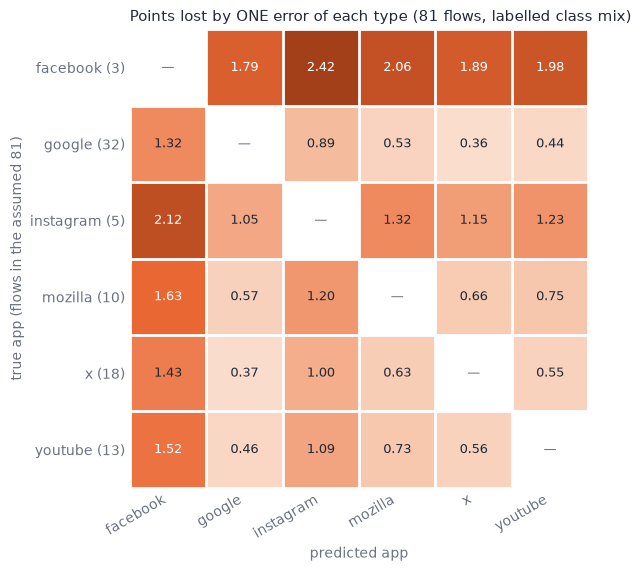

In [6]:
MIX = {"facebook": 3, "google": 32, "instagram": 5, "mozilla": 10, "x": 18, "youtube": 13}


def points_lost(errors):
    """Points lost (50 x (1 - macro F1)) on a MIX-sized set when `errors` [(true, predicted), ...] are the only mistakes."""
    cm = np.diag([MIX[a] for a in APPS]).astype(float)
    for t, p in errors:
        i, j = APPS.index(t), APPS.index(p)
        cm[i, i] -= 1
        cm[i, j] += 1
    tp, fp, fn = np.diag(cm), cm.sum(axis=0) - np.diag(cm), cm.sum(axis=1) - np.diag(cm)
    f1 = np.divide(2 * tp, 2 * tp + fp + fn, out=np.zeros(6), where=(2 * tp + fp + fn) > 0)
    return 50 * (1 - f1.mean())


COST = pd.DataFrame([[np.nan if t == p else points_lost([(t, p)]) for p in APPS] for t in APPS], index=APPS, columns=APPS)

fig, ax = plt.subplots(figsize=(7.4, 5.6), constrained_layout=True)
ORANGES = LinearSegmentedColormap.from_list("oranges", ["#fdf1ea", "#f7c4a8", "#eb6834", "#a3401a"])
ax.imshow(COST.values, cmap=ORANGES, vmin=0, vmax=np.nanmax(COST.values))
for i in range(6):
    for j in range(6):
        v = COST.values[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9.5,
                color=MUTED if np.isnan(v) else ("white" if v > 0.6 * np.nanmax(COST.values) else INK))
ax.set_xticks(np.arange(-0.5, 6), minor=True)
ax.set_yticks(np.arange(-0.5, 6), minor=True)
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
ax.set_xticks(range(6), APPS, rotation=30, ha="right")
ax.set_yticks(range(6), [f"{a} ({MIX[a]})" for a in APPS])
for s in ax.spines.values():
    s.set_visible(False)
ax.set_xlabel("predicted app")
ax.set_ylabel("true app (flows in the assumed 81)")
ax.set_title("Points lost by ONE error of each type (81 flows, labelled class mix)", loc="left", fontsize=11, color=INK)
plt.show()

In [7]:
off = COST.stack()
fb = off[[("facebook" in k) for k in off.index]]
print(f"cheapest single error: {off.idxmin()[0]} -> {off.idxmin()[1]} = {off.min():.2f} points")
print(f"most expensive:        {off.idxmax()[0]} -> {off.idxmax()[1]} = {off.max():.2f} points")
print(f"any error involving facebook costs {fb.min():.2f} to {fb.max():.2f} points; "
      f"involving instagram (not facebook): {off[[('instagram' in k and 'facebook' not in k) for k in off.index]].min():.2f} "
      f"to {off[[('instagram' in k and 'facebook' not in k) for k in off.index]].max():.2f}")
print()
for name in [L.index[0], L.index[1], "Telex"]:
    r = L.loc[name]
    print(f"{name:10s} Task 1: {r['T1 errors']} errors, {r['T1 points per error']:.2f} points each | "
          f"Task 2: {r['T2 errors']} errors, {r['T2 points per error']:.2f} points each")

cheapest single error: google -> x = 0.36 points
most expensive:        facebook -> instagram = 2.42 points
any error involving facebook costs 1.32 to 2.42 points; involving instagram (not facebook): 0.89 to 1.32

Infralibre Task 1: 4 errors, 0.45 points each | Task 2: 7 errors, 0.46 points each
HeriTech   Task 1: 4 errors, 0.54 points each | Task 2: 6 errors, 0.48 points each
Telex      Task 1: 8 errors, 0.55 points each | Task 2: 9 errors, 0.53 points each


## 4. Where we lose points now (the submitted file)

Section 2 showed where our errors fall; section 3 what one error of each type costs. Multiplying the two gives **expected points lost
per confusion cell**: expected wrong flows per 81 (cross-validation, scaled) × points per error. For Task 1 the submitted file is
upload 10: production 100 plus the count rule of experiment 127 (099 rule D), applied to production's out-of-fold predictions with the
instagram scores traced in experiment 098 on the same folds, as in notebook 07. Task 2 is production 014. Costs only roughly add up,
and cross-validation is not the test set (upload 10 scored better on the test than its CV suggests), so read this as **where the
risk sits**, not where any test error is.

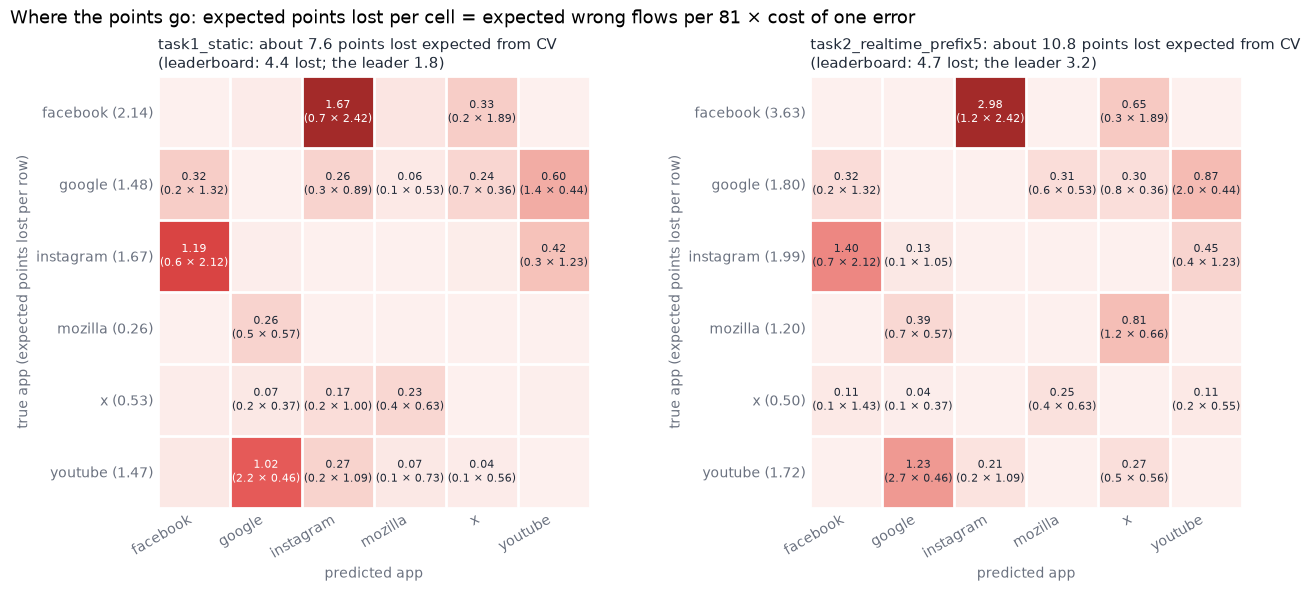

task2  facebook -> instagram  2.98 points
task1  facebook -> instagram  1.67 points
task2  instagram -> facebook  1.40 points
task2  youtube -> google      1.23 points
task1  instagram -> facebook  1.19 points
task1  youtube -> google      1.02 points
task2  google -> youtube      0.87 points
task2  mozilla -> x           0.81 points
{'task1_static': 'Meta-involving cells 4.95 of 7.56 points', 'task2_realtime_prefix5': 'Meta-involving cells 6.26 of 10.84 points'}


In [8]:
def rule_d_oof(task="task1_static", base="20261012T154049Z_100_production_check_s2026"):
    """Upload 10's rule on production's out-of-fold predictions (same as notebook 07)."""
    o = pd.read_csv(ROOT / "results" / base / task / "oof.csv")
    tr = pd.read_csv(ROOT / "experiments/098_evidence/trace_all.csv")
    tr["s_ig"] = (tr.pw_ig + tr.po_ig + tr.pr_ig) / 3
    o = o.merge(tr[["fold", "flow_id", "s_ig"]], on=["fold", "flow_id"], how="left")
    ig_all = int((o[o.fold < 5].y_true == "instagram").sum())
    for f, g in o.groupby("fold"):
        E = int(round(len(g) * (ig_all - (g.y_true == "instagram").sum()) / (330 - len(g))))
        k = max(0, E - int((g.y_pred == "instagram").sum()))
        o.loc[g[g.y_pred != "instagram"].nlargest(k, "s_ig").index, "y_pred"] = "instagram"
    return o


SUBMITTED = {"task1_static": rule_d_oof(),
             "task2_realtime_prefix5": pd.read_csv(ROOT / "results" / champions["task2_realtime_prefix5"]["run_id"]
                                                   / "task2_realtime_prefix5" / "oof.csv")}
cost = COST.fillna(0).values
REDS = LinearSegmentedColormap.from_list("reds", ["#fdf0ee", "#f4b4ab", "#e34948", "#a32a29"])
LOSS = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), constrained_layout=True)
for ax, (task, oof) in zip(axes, SUBMITTED.items()):
    cm = confusion_matrix(oof.y_true, oof.y_pred, labels=APPS) / 10 * N_TEST / 330
    loss = cm * cost
    LOSS[task] = loss
    ax.imshow(loss, cmap=REDS, vmin=0, vmax=max(loss.max(), 0.01))
    for i in range(6):
        for j in range(6):
            if i != j and cm[i, j] >= 0.05:
                ax.text(j, i, f"{loss[i, j]:.2f}\n({cm[i, j]:.1f} × {cost[i, j]:.2f})", ha="center", va="center", fontsize=8,
                        color="white" if loss[i, j] > 0.6 * loss.max() else INK)
    ax.set_xticks(np.arange(-0.5, 6), minor=True)
    ax.set_yticks(np.arange(-0.5, 6), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", length=0)
    ax.set_xticks(range(6), APPS, rotation=30, ha="right")
    ax.set_yticks(range(6), [f"{a} ({loss[i].sum():.2f})" for i, a in enumerate(APPS)])
    for s in ax.spines.values():
        s.set_visible(False)
    t = 1 if task == "task1_static" else 2
    ax.set_xlabel("predicted app")
    ax.set_ylabel("true app (expected points lost per row)")
    ax.set_title(f"{task}: about {loss.sum():.1f} points lost expected from CV\n"
                 f"(leaderboard: {L.loc['Telex', f'T{t} points lost']:.1f} lost; the leader {L.iloc[0][f'T{t} points lost']:.1f})",
                 loc="left", fontsize=11, color=INK)
fig.suptitle("Where the points go: expected points lost per cell = expected wrong flows per 81 × cost of one error",
             x=0.01, ha="left", fontsize=13)
plt.show()

rows = [(LOSS[t][i, j], t.split("_")[0], f"{APPS[i]} -> {APPS[j]}") for t in LOSS for i in range(6) for j in range(6) if i != j]
for v, t, name in sorted(rows, reverse=True)[:8]:
    print(f"{t:6s} {name:22s} {v:.2f} points")
meta = {t: sum(LOSS[t][i, j] for i in range(6) for j in range(6) if i != j and ({APPS[i], APPS[j]} & {"facebook", "instagram"}))
        for t in LOSS}
print({t: f"Meta-involving cells {meta[t]:.2f} of {LOSS[t].sum():.2f} points" for t in LOSS})

## Summary

1. **The gap is now 4.2 points, mostly Task 1.** Against the leader's 16 October entry (95.01) we are at 90.85 since upload 10
   (21 October): 2.6 points behind in Task 1 and 1.5 in Task 2. Other teams may have moved since 16 October.
2. **Task 1 changed from "expensive errors" to "more errors".** Before upload 10 we had 7 Task 1 errors at 1.02 points each; now 8
   errors at 0.55 each, close to the leaders' 0.45-0.54. The remaining Task 1 gap is the count: 8 errors against the leaders' 4.
   (This reads the leaderboard's public numbers only; it does not say which of our test flows are wrong.)
3. **Price is still the story behind each error.** One error costs between 0.36 points (google → x) and 2.42 points (facebook →
   instagram) on a test-sized set with the labelled class mix. Every error involving facebook costs at least 1.32 points;
   instagram errors 0.89 or more. The class mix is an assumption from labelled proportions, and costs only roughly add up.
4. **Task 2 is close to the leaders.** We have 9 errors at 0.53 points each, against 7 at 0.46 for the leader. Our Task 2 test
   score (0.905) is far above its cross-validation level (0.754, about 12 expected errors per 81).
5. **Cross-validation expects about 8 Task 1 errors per 81** (the scaled matrices above), which is what the test shows now. The
   largest expected cells are youtube → google (2.2), google → youtube (1.4) and instagram → facebook (0.8).
6. **Where we lose points now (section 4): facebook and instagram.** Cells involving them hold 4.95 of the 7.6 expected Task 1
   points and 6.3 of the 10.8 expected Task 2 points. The single most expensive cell is **facebook called instagram**: 3.0 expected
   points in Task 2 and 1.7 in Task 1 (each mistake costs 2.42), then instagram called facebook (1.4 and 1.2), then youtube called
   google (1.2 and 1.0, many cheap mistakes). Cross-validation expects more loss than the test showed (Task 1 7.6 vs 4.4 lost on
   the leaderboard; Task 2 10.8 vs 4.7), so this ranks the risk, not the test errors.
